[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch43_LabCh43_Tool_Loop.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 43: Tools and Agents** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=43](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=43)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch43 - The Tool Loop
## A tiny model that cannot multiply, a calculator that can, and the loop that joins them

This lab goes with **Chapter 43** of *The Why Book of Deep Learning, Part 2*.

A language model can only write text. In this lab some of that text becomes a request to run a function.
You train the book's small transformer **two ways** on the same arithmetic questions:

* the **direct** model writes the answer itself: `37*46?` → `=1702`
* the **tool-calling** model writes a call, `CALC(37*46)`, which *your code* parses and runs. The result is
  appended to the text, and the model then writes the answer.

Then you test both on questions of a kind neither has seen, build the general loop (parse, validate, execute,
append, repeat, with a step limit and a log), and break it on purpose: a tool that fails, a tool that lies,
and a calculation that is wrong a little at every step.

| The model | value |
|---|---|
| design | TinyGPT of Chapter 35: decoder-only, pre-norm, 2 blocks, width 64, 4 heads, feed-forward 256 |
| context T | 64 characters |
| vocabulary V | 22 characters: newline, ten digits, `+ * ? = ( ) >` and the letters `C A L E` |
| trained | twice from nothing, inside this notebook: once per style |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write the same task as "answer directly" and as "call a tool", and grade only the model's own turns | Steps 3 to 5 |
| Say who executes a tool call (not the model) and write the parser that does it safely | Step 10 |
| Measure a tool-caller three ways: right answer, malformed call, well-formed call with wrong arguments | Steps 12 and 13 |
| Write a general tool loop with a step limit, an error path and a log you can read | Step 14 |
| Predict what a model does with a failing tool and with a wrong tool result | Steps 15 to 17 |
| Add two guards (check the call, check the answer) and count what each catches | Step 18 |
| Compute how fast small per-step errors eat a multi-step task | Step 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** four to five minutes on a laptop CPU, most of it in the two training cells (Steps 8 and 11).
> No GPU, no downloads: the data are sums and products made inside the notebook.

> **Honest scale:** this is a miniature. The model has about a hundred thousand parameters and knows 22
> characters. It learns its tool format by being trained on it; a full-size assistant is *told* about its tools
> in the prompt and has never seen most of them before. What carries over is the plumbing and the ways it
> fails, not the numbers.

---
## Step 1 - Imports and one seed

In [1]:
import os, re, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 43
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Twenty-two characters

Everything the model reads or writes is made of these characters. One character is one token (Chapter 33's
smallest tokenizer). The newline has id 0: it ends every line, and it also fills the unused right-hand end of
a row.

| characters | used for |
|---|---|
| `0` to `9` | numbers |
| `+` `*` `?` | the question: `37*46?` |
| `C A L ( )` | a tool call: `CALC(37*46)` |
| `>` and `E` | a line written by the harness: `>1702` is a tool result, `>E` is an error |
| `=` | the model's final answer: `=1702` |

> **Predict:** the loss of a model that guesses blindly among 22 characters is ln 22. Roughly what is it?

In [2]:
ALPHABET = "\n0123456789+*?=()>CALE"
V = len(ALPHABET)
char_to_id = {ch: i for i, ch in enumerate(ALPHABET)}
CONTEXT = 64


def encode(text):
    return [char_to_id[ch] for ch in text]


def decode(ids):
    return "".join(ALPHABET[int(i)] for i in ids)


print("V =", V, "| ln V =", round(float(np.log(V)), 3))
print(encode("37*46?\n"), "->", repr(decode(encode("37*46?\n"))))

V = 22 | ln V = 3.091
[4, 8, 12, 5, 7, 13, 0] -> '37*46?\n'


---
## Step 3 - The questions, and the kind we hold back

A question is two whole numbers and `+` or `*`. In training each number has one, two or three digits (three
digits half the time), with one rule: **the two numbers are never both 500 or more**.

That rule leaves a corner of the map unvisited, and gives us three test sets of 500 questions each:

| test set | the numbers | seen in training? |
|---|---|---|
| `seen kind` | drawn like the training questions | the kind yes, these exact questions no (they are kept out) |
| `both large` | both between 500 and 999 | each number alone yes, the pair never. Products run from 250,000 to 998,001 |
| `longer` | both between 1,000 and 9,999 | never: four digits is longer than anything in training |

> **Predict:** in `both large`, every digit and every position is familiar. Only the combination is new.
> Is that enough to break a model that writes the answer itself? And one that only has to copy the question
> into a call?

In [3]:
def calculator(a, op, b):
    """The tool. Ordinary software: exact, instant, and unable to read a question."""
    return a + b if op == "+" else a * b


def random_number(rng):
    n_digits = 1 + int(rng.choice(3, p=[0.2, 0.3, 0.5]))
    low = 0 if n_digits == 1 else 10 ** (n_digits - 1)
    return int(rng.integers(low, 10 ** n_digits))


def make_questions(kind, n, rng, keep_out=frozenset()):
    """n questions (a, op, b) of one kind, none of them in keep_out."""
    out = []
    while len(out) < n:
        op = "+*"[len(out) % 2]
        if kind == "longer":
            a, b = int(rng.integers(1000, 10000)), int(rng.integers(1000, 10000))
        elif kind == "both large":
            a, b = int(rng.integers(500, 1000)), int(rng.integers(500, 1000))
        else:
            a, b = random_number(rng), random_number(rng)
            if a >= 500 and b >= 500:
                continue                                   # the corner training never visits
        if (a, op, b) not in keep_out:
            out.append((a, op, b))
    return out


test_rng = np.random.default_rng(7)
TESTS = {kind: make_questions(kind, 500, test_rng) for kind in ["seen kind", "both large", "longer"]}
KEEP_OUT = frozenset(TESTS["seen kind"])
for kind, qs in TESTS.items():
    shown = "   ".join(f"{a}{op}{b}" for a, op, b in qs[:5])
    print(f"{kind:11s} {len(qs)} questions, e.g.  {shown}")
largest_trainable = max(499 * 999, 999 * 499)
print(f"largest product training can contain: 499 x 999 = {largest_trainable:,}")
share = np.mean([a * b > largest_trainable for a, op, b in TESTS["both large"] if op == "*"])
print(f"'both large' products above that: {share:.0%}")

seen kind   500 questions, e.g.  14+370   4*839   83+37   99*500   406+99
both large  500 questions, e.g.  991+671   650*827   999+765   984*843   898+623
longer      500 questions, e.g.  3796+6183   9985*3337   2597+7780   6612*4374   7284+5306
largest product training can contain: 499 x 999 = 498,501
'both large' products above that: 62%


---
## Step 4 - One question, two ways to write the lesson

A training example is a short **transcript**. The two styles differ only in what the model is asked to write.

```
direct                tool-calling
37*46?                37*46?            <- the question (given)
=1702                 CALC(37*46)       <- the model writes a call, and stops at the newline
                      >1702             <- the harness ran the calculator and wrote the result (given)
                      =1702             <- the model writes the answer
```

Two more choices shape what the tool-caller learns.

* In one tool transcript out of ten the first call comes back as `>E` (an error) and the model's correct next
  move is to call again. That is the only error handling it is ever taught.
* In one tool transcript out of four the tool returns **not the true result but a random number**, and the
  graded answer repeats that number. Why would anyone train on wrong results? Because otherwise the model has
  two ways to produce its answer, repeating the tool or working the sum out itself, and it learns a blend of
  the two that falls apart on unfamiliar numbers. We want one behaviour only: *report what the tool said*. The
  calculator is better at arithmetic than the model will ever be. (Step 17 looks at the price of that trust.)

Each piece of a transcript is marked **graded** or **given**. Only graded characters count in the loss: the
model is not asked to predict the question (it is random) or the tool's result (it cannot). It is graded on
its own turns only, which is how chat models are fine-tuned too (Chapter 39).

> **Predict:** in the tool transcript, which graded characters require arithmetic? Which require only copying?

In [4]:
def transcript(a, op, b, style, retry=False, shown=None):
    """One training transcript as a list of (text, graded) pieces.
    shown: what the tool returns in this transcript (default: the true result)."""
    question = f"{a}{op}{b}?\n"
    result = str(calculator(a, op, b))
    if style == "direct":
        return [(question, 0), (f"={result}\n", 1)]
    result = result if shown is None else str(shown)
    call = f"CALC({a}{op}{b})\n"
    pieces = [(question, 0)]
    if retry:
        pieces += [(call, 1), (">E\n", 0)]
    return pieces + [(call, 1), (f">{result}\n", 0), (f"={result}\n", 1)]


for style, retry, shown, title in [("direct", False, None, "direct"), ("tool", False, None, "tool"),
                                   ("tool", True, None, "tool, with one failed call"),
                                   ("tool", False, 905, "tool, with a result that is not the true one")]:
    print(f"--- {title}")
    for text, graded in transcript(37, "*", 46, style, retry, shown):
        print(f"   {'graded' if graded else 'given ':6s}  {text!r}")
longest = sum(len(t) for t, _ in transcript(999, "*", 999, "tool", True))
print(f"\nlongest training transcript: {longest} characters (the context holds {CONTEXT})")

--- direct
   given   '37*46?\n'
   graded  '=1702\n'
--- tool
   given   '37*46?\n'
   graded  'CALC(37*46)\n'
   given   '>1702\n'
   graded  '=1702\n'
--- tool, with one failed call
   given   '37*46?\n'
   graded  'CALC(37*46)\n'
   given   '>E\n'
   graded  'CALC(37*46)\n'
   given   '>1702\n'
   graded  '=1702\n'
--- tool, with a result that is not the true one
   given   '37*46?\n'
   graded  'CALC(37*46)\n'
   given   '>905\n'
   graded  '=905\n'

longest training transcript: 56 characters (the context holds 64)


---
## Step 5 - Transcripts become arrays

As in Chapter 35, the target is the input shifted left by one. The new part is `w`, the weight of each
position in the loss: 1 where the target character is graded, 0 elsewhere (given text and padding).

> **Predict:** for the direct transcript `37*46?` / `=1702`, how many positions have weight 1?

In [5]:
def make_rows(style, n, rng):
    """n training rows: x (n, CONTEXT) inputs, y (n, CONTEXT) targets, w (n, CONTEXT) loss weights."""
    ids = np.zeros((n, CONTEXT + 1), np.int32)
    graded = np.zeros((n, CONTEXT + 1), np.float32)
    questions = make_questions("seen kind", n, rng, keep_out=KEEP_OUT)
    for i, (a, op, b) in enumerate(questions):
        p = 0
        retry = rng.random() < 0.1
        shown = None
        if style == "tool" and rng.random() < 0.25:        # a tool result that is not the true one
            shown = int(rng.integers(0, 10 ** int(rng.integers(1, 7))))
        for text, g in transcript(a, op, b, style, retry, shown):
            ids[i, p:p + len(text)] = encode(text)
            graded[i, p:p + len(text)] = g
            p += len(text)
    return ids[:, :-1], ids[:, 1:], graded[:, 1:]


for style in ["direct", "tool"]:
    x, y, w = make_rows(style, 2000, np.random.default_rng(1))
    print(f"{style:6s} x {x.shape}  y {y.shape}  w {w.shape}   graded positions per row: {w.sum(axis=1).mean():.1f} of {CONTEXT}")
x, y, w = make_rows("direct", 1, np.random.default_rng(5))
n_used = int(np.argmax(np.cumsum(w[0]))) + 1
print("\none direct row:")
print("  input :", repr(decode(x[0, :n_used])))
print("  target:", repr(decode(y[0, :n_used])))
print("  weight:", " ".join(str(int(v)) for v in w[0, :n_used]))

direct x (2000, 64)  y (2000, 64)  w (2000, 64)   graded positions per row: 5.5 of 64


tool   x (2000, 64)  y (2000, 64)  w (2000, 64)   graded positions per row: 19.4 of 64



one direct row:
  input : '120+827?\n=947'
  target: '20+827?\n=947\n'
  weight: 0 0 0 0 0 0 0 0 1 1 1 1 1


---
## Step 6 - Count, then build

The model is `build_tinygpt()` from Chapter 35, copied unchanged. Only the vocabulary differs: 22 characters
instead of 39. The hand count is the same formula.

> **Predict:** Chapter 35's TinyGPT had 109,223 parameters with V = 39. The token table has V·64 numbers and
> the head has 64·V + V. How many parameters go when V falls by 17?

In [6]:
def count_tinygpt(vocab_size, d=64, blocks=2, ff=256, context=64):
    token_table = vocab_size * d
    position_table = context * d
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    one_block = attention + feed_forward + 2 * (2 * d)
    return token_table + position_table + blocks * one_block + 2 * d + (d * vocab_size + vocab_size)


class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, name="TinyGPT"):
    """TinyGPT (Chapter 35): decoder-only, pre-norm, learnt positions, untied head.
    ids (batch, context) -> logits (batch, context, vocab_size)."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=True)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name=name)


hand_total = count_tinygpt(V)
direct_model = build_tinygpt(V, name="direct")
tool_model = build_tinygpt(V, name="tool_caller")
print(f"hand count: {hand_total:,}   Keras: {direct_model.count_params():,} and {tool_model.count_params():,}")
print(f"Chapter 35's count with V = 39 was 109,223: {109_223 - hand_total:,} fewer here (17 x 64 + 17 x 65)")
assert direct_model.count_params() == tool_model.count_params() == hand_total == 107_030
print("shapes: ids", direct_model.input_shape, "-> logits", direct_model.output_shape)

hand count: 107,030   Keras: 107,030 and 107,030
Chapter 35's count with V = 39 was 109,223: 2,193 fewer here (17 x 64 + 17 x 65)
shapes: ids (None, 64) -> logits (None, 64, 22)


### Why we see this

Two models, the same 107,030 weights each, the same random start in distribution. Whatever differs at the end
of this lab comes from **what each was asked to write**, not from size.

---
## Step 7 - The first loss, and a way to take one turn

Two helpers used for the rest of the lab.

`graded_loss()` is the cross-entropy averaged over the graded positions only. Before training it should sit
near ln 22.

`model_turn()` lets the model write **one line**: it picks the most likely next character again and again
(greedy decoding, Chapter 36) until it writes a newline. It works on many contexts at once, because one call
on 500 rows is far faster than 500 calls. A turn that runs to 24 characters without a newline is cut off.

> **Predict:** what does an untrained model write when it is given `37*46?` and asked for one line?

In [7]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction=None)


def graded_loss(model, x, y, w):
    per_position = loss_fn(y, model.predict(x, batch_size=500, verbose=0)).numpy()
    return float((per_position * w).sum() / w.sum())


def model_turn(model, contexts, max_new=24):
    """Continue each context by one line (greedy). Returns the new lines, each ending in a newline
    unless it was cut off at max_new characters."""
    texts = list(contexts)
    lines = [""] * len(texts)
    live = list(range(len(texts)))
    for _ in range(max_new):
        if not live:
            break
        buf = np.zeros((len(live), CONTEXT), np.int32)
        last = []
        for row, i in enumerate(live):
            recent = encode(texts[i])[-CONTEXT:]            # if the text is too long, the start falls off
            buf[row, :len(recent)] = recent
            last.append(len(recent) - 1)
        logits = model.predict_on_batch(buf)
        still = []
        for row, i in enumerate(live):
            ch = ALPHABET[int(logits[row, last[row]].argmax())]
            texts[i] += ch
            lines[i] += ch
            if ch != "\n":
                still.append(i)
        live = still
    return lines


val = {style: make_rows(style, 1000, np.random.default_rng(2)) for style in ["direct", "tool"]}
print(f"ln V = {np.log(V):.3f}")
print(f"direct model, before training: graded loss {graded_loss(direct_model, *val['direct']):.3f}")
print(f"tool model,   before training: graded loss {graded_loss(tool_model, *val['tool']):.3f}")
print("an untrained turn:", [repr(t) for t in model_turn(direct_model, ["37*46?\n", "5+5?\n"])])

ln V = 3.091


direct model, before training: graded loss 3.121


tool model,   before training: graded loss 3.103


an untrained turn: ["'11111010141A111414?11114'", "'7))11A11A1141A41141A1141'"]


---
## Step 8 - Train the direct model

The recipe of Chapter 35: AdamW, warm-up then cosine decay, gradient clipping. 2,000 steps of 64 fresh
questions, so 128,000 questions in all. There are about a million possible pairs of numbers and two
operations, so the model sees almost every question at most once: it has to learn a method, not a table.

> **Predict:** which will it learn better in 2,000 steps, addition or multiplication? Why should the two differ?

> A slow cell: about a minute and three quarters.

In [8]:
def train(model, style, steps, batch=64, peak_lr=3e-3, rounds=4):
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=peak_lr, warmup_steps=100, decay_steps=steps - 100, alpha=0.05)
    model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    t0 = time.time()
    for r in range(1, rounds + 1):
        x, y, w = make_rows(style, steps // rounds * batch, rng)
        model.fit(x, y, sample_weight=w, batch_size=batch, epochs=1, shuffle=False, verbose=0)
        print(f"  step {r * steps // rounds:5d}   graded loss {graded_loss(model, *val[style]):.4f}   [{time.time() - t0:3.0f}s]")
    return time.time() - t0


DIRECT_STEPS = 2000
print("training the direct model")
direct_seconds = train(direct_model, "direct", DIRECT_STEPS)

training the direct model


  step   500   graded loss 1.1791   [ 37s]


  step  1000   graded loss 1.0153   [ 71s]


  step  1500   graded loss 0.7219   [109s]


  step  2000   graded loss 0.5900   [132s]


---
## Step 9 - Test the direct model

One score only: is the line it writes exactly `=` followed by the right number?

> **Predict:** its accuracy on `seen kind`, on `both large` and on `longer`. Then guess what a wrong answer
> looks like: nonsense, or a number of about the right size?

In [9]:
def ask_direct(model, questions):
    lines = model_turn(model, [f"{a}{op}{b}?\n" for a, op, b in questions])
    right = np.array([line == f"={calculator(a, op, b)}\n" for line, (a, op, b) in zip(lines, questions)])
    return right, lines


def by_op(questions, flags, op):
    return float(np.mean([f for f, q in zip(flags, questions) if q[1] == op]))


direct_scores = {}
print(f"{'direct model':12s} {'a + b':>7s} {'a * b':>7s}")
for kind, qs in TESTS.items():
    right, lines = ask_direct(direct_model, qs)
    direct_scores[kind] = (by_op(qs, right, "+"), by_op(qs, right, "*"), float(right.mean()))
    print(f"{kind:12s} {direct_scores[kind][0]:7.1%} {direct_scores[kind][1]:7.1%}")
    for (a, op, b), line, ok in list(zip(qs, lines, right))[:4]:
        print(f"      {a}{op}{b} = {calculator(a, op, b):<10,} model: {line.strip():10s} {'right' if ok else 'WRONG'}")

qs = TESTS["seen kind"]
right, _ = ask_direct(direct_model, qs)
print("\n'seen kind', by the length of the longer number:")
for digits in [1, 2, 3]:
    pick = [max(len(str(a)), len(str(b))) == digits for a, op, b in qs]
    for op in "+*":
        sel = [r for r, p, q in zip(right, pick, qs) if p and q[1] == op]
        print(f"   {digits} digit{'s' if digits > 1 else ' '} {op}   {np.mean(sel):6.1%}   ({len(sel)} questions)")

direct model   a + b   a * b


seen kind      69.6%   15.6%
      14+370 = 384        model: =384       right
      4*839 = 3,356      model: =3626      WRONG
      83+37 = 120        model: =110       WRONG
      99*500 = 49,500     model: =48600     WRONG


both large      6.4%    0.0%
      991+671 = 1,662      model: =1351      WRONG
      650*827 = 537,550    model: =500060    WRONG
      999+765 = 1,764      model: =1364      WRONG
      984*843 = 829,512    model: =854472    WRONG


longer          0.0%    0.0%
      3796+6183 = 9,979      model:            WRONG
      9985*3337 = 33,319,945 model: =39        WRONG
      2597+7780 = 10,377     model:            WRONG
      6612*4374 = 28,920,888 model: =          WRONG



'seen kind', by the length of the longer number:
   1 digit  +   100.0%   (8 questions)
   1 digit  *    92.3%   (13 questions)
   2 digits +    83.9%   (62 questions)
   2 digits *    28.1%   (57 questions)
   3 digits +    63.3%   (180 questions)
   3 digits *     6.1%   (180 questions)


### Why we see this

**Inside the kind it trained on**, the direct model gets about two sums in three and one product in six: it
has learnt addition in part and multiplication hardly at all beyond the small cases. Look at the wrong answers: they have the right number of digits and often the
right first and last digit. The model has learnt what an answer *looks like* long before it has learnt how to
work one out. That is the worrying property: a wrong answer here does not look wrong.

Why multiplication is harder: every digit of a product depends on every digit of both numbers, with carries
rippling through. A person does it with a column of intermediate results. This model has two blocks and must
write the first digit of the answer in one pass, with no scratch paper (Chapter 41's reason for asking a model
to write its steps).

**`both large`** is the important row. Every number in it has been seen, in the same place, thousands of
times. Only the pairing is new, and the direct model falls to nearly nothing. It did not learn arithmetic. It
learnt a patchwork that covers the region it was shown.

**`longer`** is hopeless in a different way: the model has never seen a four-digit number, and its position
table has never held a question that long.

More steps and a bigger model would raise the first row a great deal. They would move the corner you held
back much less, and there is always a corner.

---
## Step 10 - Who runs the tool? Not the model

The tool-calling model will write text such as `CALC(37*46)`. That text does nothing. A program has to read
it, decide whether it is a call at all, pull out the arguments, and run a function. That program is the
**harness**, and it starts with a parser.

The parser below is deliberately strict: one regular expression that accepts exactly `CALC(` digits, `+` or
`*`, digits, `)` and a newline. Anything else is **malformed**. Note what it does *not* do: it never hands the
model's text to Python's `eval`. The model's output is data to be checked, never code to be run.

> **Predict:** which of these six lines does the parser accept?

In [10]:
CALL_PATTERN = re.compile(r"CALC\((\d+)([+*])(\d+)\)\n")


def parse_call(line):
    """'CALC(37*46)\\n' -> (37, '*', 46). Anything else -> None."""
    m = CALL_PATTERN.fullmatch(line)
    return (int(m.group(1)), m.group(2), int(m.group(3))) if m else None


for line in ["CALC(37*46)\n", "CALC(37*46\n", "CALC(37x46)\n", "CALC(*46)\n", "=1702\n", "CALC(37*46)"]:
    print(f"{line!r:18s} -> {parse_call(line)}")

'CALC(37*46)\n'    -> (37, '*', 46)
'CALC(37*46\n'     -> None
'CALC(37x46)\n'    -> None
'CALC(*46)\n'      -> None
'=1702\n'          -> None
'CALC(37*46)'      -> None


---
## Step 11 - Train the tool-caller

Same model, same questions, same recipe, and **fewer** steps: 1,200 against the direct model's 2,000. The
only other change is the transcript style of Step 4.

> **Predict:** its graded loss will fall much lower than the direct model's, and much sooner. Why? (Look back
> at your answer to Step 4: what does it have to work out?)

> The other slow cell: about a minute.

In [11]:
TOOL_STEPS = 1200
print("training the tool-calling model")
tool_seconds = train(tool_model, "tool", TOOL_STEPS)
print(f"\ndirect model: {DIRECT_STEPS} steps, {direct_seconds:.0f} s, final graded loss {graded_loss(direct_model, *val['direct']):.4f}")
print(f"tool model:   {TOOL_STEPS} steps, {tool_seconds:.0f} s, final graded loss {graded_loss(tool_model, *val['tool']):.4f}")

training the tool-calling model


  step   300   graded loss 0.0701   [ 21s]


  step   600   graded loss 0.0419   [ 36s]


  step   900   graded loss 0.0142   [ 51s]


  step  1200   graded loss 0.0089   [ 65s]



direct model: 2000 steps, 132 s, final graded loss 0.5900


tool model:   1200 steps, 65 s, final graded loss 0.0089


---
## Step 12 - Test the tool-caller, and count three kinds of failure

A tool-caller can fail in ways a direct model cannot, so one accuracy number is not enough. For each question:

1. the model takes a turn. Is it a **well-formed call**? If the parser rejects it, count it as *malformed*.
2. Are the arguments the ones in the question? A call that parses but asks for the wrong sum is counted as
   *wrong arguments*. The parser cannot see this failure.
3. The harness runs the calculator on whatever the call asked for, appends `>result`, and the model takes a
   second turn. Is that line `=` and the right number?

> **Predict:** fill in this table before you run the cell: right answers, malformed calls and wrong-argument
> calls, for each of the three test sets.

tool-caller    a + b   a * b   malformed wrong args  call right, answer wrong


seen kind     100.0%  100.0%        0.0%       0.0%                      0.0%


both large    100.0%  100.0%        0.0%       0.0%                      0.0%


longer          0.0%    0.0%      100.0%       0.0%                      0.0%

both models, all 500 questions of each set:
   seen kind    direct  42.6%    tool-caller 100.0%
   both large   direct   3.2%    tool-caller 100.0%
   longer       direct   0.0%    tool-caller   0.0%


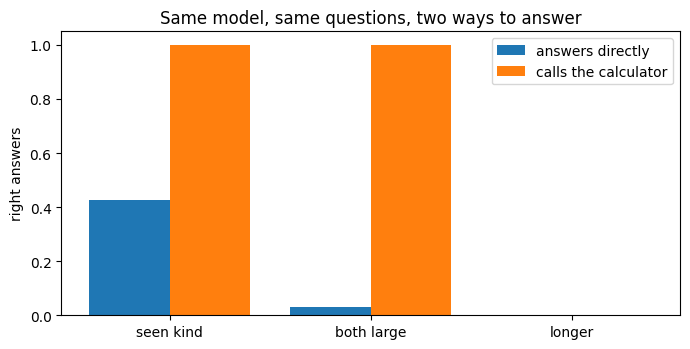

In [12]:
def ask_with_tool(model, questions, tool=calculator):
    """Two turns per question: call, then answer. Returns a list of outcome dicts."""
    prompts = [f"{a}{op}{b}?\n" for a, op, b in questions]
    first = model_turn(model, prompts)
    out, second_ctx, second_idx = [], [], []
    for i, ((a, op, b), line) in enumerate(zip(questions, first)):
        call = parse_call(line)
        rec = {"call_line": line, "malformed": call is None, "wrong_args": call is not None and call != (a, op, b),
               "answer_line": "", "right": False}
        if call is not None:
            second_ctx.append(prompts[i] + line + f">{tool(*call)}\n")
            second_idx.append(i)
        out.append(rec)
    for i, line in zip(second_idx, model_turn(model, second_ctx)):
        a, op, b = questions[i]
        out[i]["answer_line"] = line
        out[i]["right"] = line == f"={calculator(a, op, b)}\n"
    return out


tool_scores, tool_runs = {}, {}
print(f"{'tool-caller':12s} {'a + b':>7s} {'a * b':>7s}   {'malformed':>9s} {'wrong args':>10s} {'call right, answer wrong':>25s}")
for kind, qs in TESTS.items():
    runs = ask_with_tool(tool_model, qs)
    tool_runs[kind] = runs
    right = [r["right"] for r in runs]
    malformed = float(np.mean([r["malformed"] for r in runs]))
    wrong_args = float(np.mean([r["wrong_args"] for r in runs]))
    miscopied = float(np.mean([(not r["malformed"]) and (not r["wrong_args"]) and (not r["right"]) for r in runs]))
    tool_scores[kind] = (by_op(qs, right, "+"), by_op(qs, right, "*"), float(np.mean(right)), malformed, wrong_args, miscopied)
    print(f"{kind:12s} {tool_scores[kind][0]:7.1%} {tool_scores[kind][1]:7.1%}   {malformed:9.1%} {wrong_args:10.1%} {miscopied:25.1%}")

print("\nboth models, all 500 questions of each set:")
for kind in TESTS:
    print(f"   {kind:12s} direct {direct_scores[kind][2]:6.1%}    tool-caller {tool_scores[kind][2]:6.1%}")

fig, ax = plt.subplots(figsize=(7, 3.6))
kinds = list(TESTS)
ax.bar(np.arange(3) - 0.2, [direct_scores[k][2] for k in kinds], 0.4, label="answers directly")
ax.bar(np.arange(3) + 0.2, [tool_scores[k][2] for k in kinds], 0.4, label="calls the calculator")
ax.set_xticks(np.arange(3)); ax.set_xticklabels(kinds); ax.set_ylabel("right answers"); ax.set_ylim(0, 1.05)
ax.set_title("Same model, same questions, two ways to answer"); ax.legend(); plt.tight_layout(); plt.show()

### Why we see this

On the kind it trained on, the tool-caller is right every time, after little more than half the training the
direct model had. On `both large`, where the direct model collapsed, it carries on untouched.

The reason is in what each model has to *do*. The direct model must compute. The tool-caller must **copy**:
the question into the call, then the result into the answer. Copying a familiar kind of string does not care
whether the numbers are large or whether the product has ever been seen. The hard part was handed to
software that cannot get it wrong.

The last column, "call right, answer wrong", is the reminder that a tool-using system has a model at *both*
ends of the tool: the calculator can be right and the model can still miscopy its result. It is zero here
because of the design choice in Step 4 (random tool results, so that the model learns to repeat and not to
recompute). Trial 8 removes that choice.

---
## Step 13 - Look at the failures on `longer`

`longer` is the row to read slowly. The numbers have four digits, and the tool-caller never copied a
four-digit number in its life.

> **Predict:** it cannot copy what it has never copied. But *how* will it fail: a call the parser rejects, a
> clean call with the wrong numbers, or an answer with no call at all?

In [13]:
runs = tool_runs["longer"]
qs = TESTS["longer"]
skipped_tool = [r["call_line"].startswith("=") for r in runs]
cut_off = [not r["call_line"].endswith("\n") for r in runs]
print(f"of {len(runs)} 'longer' questions:")
print(f"   malformed first turn        {np.mean([r['malformed'] for r in runs]):6.1%}")
print(f"      of which: wrote an answer without calling the tool  {np.mean(skipped_tool):6.1%}")
print(f"      of which: never finished the line (cut off)         {np.mean(cut_off):6.1%}")
print(f"   well-formed, wrong numbers  {np.mean([r['wrong_args'] for r in runs]):6.1%}")
print(f"   right answer                {np.mean([r['right'] for r in runs]):6.1%}")
print()
for (a, op, b), r in list(zip(qs, runs))[:8]:
    print(f"   {a}{op}{b}?   first turn: {r['call_line']!r:22s} second turn: {r['answer_line']!r}")

of 500 'longer' questions:
   malformed first turn        100.0%
      of which: wrote an answer without calling the tool    0.0%
      of which: never finished the line (cut off)          19.2%
   well-formed, wrong numbers    0.0%
   right answer                  0.0%

   3796+6183?   first turn: 'CALCALC(316363)*16)633)\n' second turn: ''
   9985*3337?   first turn: 'CALCALC(93)\n'        second turn: ''
   2597+7780?   first turn: 'CALCALC(27+82727)\n'  second turn: ''
   6612*4374?   first turn: 'CALCALC(63436*3)\n'   second turn: ''
   7284+5306?   first turn: 'CALCALC(73537*37)\n'  second turn: ''
   8972*9348?   first turn: 'CALCALC(83938*3)\n'   second turn: ''
   3819+7465?   first turn: 'CALCALC(347437)*4)7477)\n' second turn: ''
   5531*7626?   first turn: 'CALCALC(56765*65)\n'  second turn: ''


### Why we see this

The tool-caller is not magic. Its copying was learnt on strings of up to three digits, and a longer string
breaks it, just as a new pairing broke the direct model. It stutters (`CALCALC(`), scrambles the digits, and
in about one case in five never finishes the line. A tool does not remove a model's limits. It moves them
from "can it multiply?" to "can it write this call?".

What matters to the engineer is **how a failure shows**. There are three kinds, and a tool-using system
should be measured on each:

* A **malformed call** is a loud failure. The parser rejects it, the harness knows, and it can retry, stop or
  ask for help. Nothing wrong reaches the user. In this run, every failure on `longer` starts this way.
* A **well-formed call with the wrong arguments** is quiet: the tool returns a correct result for the wrong
  question, and the model reports it with full confidence. This run shows none. Change `TOOL_STEPS` or the
  seed and the mix changes: how a model fails outside its training is not something you can count on.
* An **answer that came from no tool result** is quiet too: to the harness a line starting with `=` is a
  perfectly valid final answer. Step 16 will produce plenty of these.

---
## Step 14 - The general loop

So far the harness was two fixed turns. A real one is a loop, because the model decides how many calls it
needs. Here is the whole thing, for any model that writes lines and any dictionary of tools:

```
repeat, at most max_steps times:
    the model writes one line
    if the line starts with "=":      it is the final answer: stop
    parse the line                    not a call? -> tell the model ">E", go round again
    validate the arguments            refused?    -> tell the model ">E", go round again
    run the tool                      it raised?  -> tell the model ">E", go round again
    append ">result" to the context
if the loop ends without an answer:   stop with "step limit"
```

Every branch writes a line to a **log**. `run_agent()` runs many questions side by side so that the notebook
stays fast; read the body as if there were one.

> **Predict:** for an easy question such as `37*46?`, how many times does the loop go round, and what are the
> log lines?

In [14]:
def run_agent(model, questions, tools, max_steps=6, validate=None, grounded=False):
    """The tool loop. questions: list of (a, op, b). tools: {"CALC": function}.
    validate(question, call) returns None if the call is acceptable, or a reason to refuse it.
    grounded=True accepts a final answer only if it equals the latest tool result.
    Returns one dict per question: status ('answered' or 'step limit'), answer, steps, log."""
    runs = [{"question": q, "context": f"{q[0]}{q[1]}{q[2]}?\n", "status": "running", "answer": None,
             "steps": 0, "last_result": None, "log": []} for q in questions]
    for step in range(1, max_steps + 1):
        live = [r for r in runs if r["status"] == "running"]
        if not live:
            break
        for r, line in zip(live, model_turn(model, [r["context"] for r in live])):
            r["steps"] = step
            call = parse_call(line)
            if line.startswith("="):                                   # the model says it has finished
                if grounded and line[1:].strip() != r["last_result"]:
                    note, observation = "refused: answer is not a tool result", "E"
                else:
                    r["status"], r["answer"] = "answered", line[1:].strip()
                    r["log"].append((step, line, "final answer", ""))
                    continue
            elif call is None:                                         # not a call at all
                note, observation = "malformed call", "E"
            else:
                refusal = validate(r["question"], call) if validate else None
                if refusal:                                            # a call we will not run
                    note, observation = f"refused: {refusal}", "E"
                else:
                    try:
                        note, observation = "tool ran", str(tools["CALC"](*call))
                        r["last_result"] = observation
                    except Exception as err:                           # the tool itself failed
                        note, observation = f"tool error: {err}", "E"
            r["log"].append((step, line, note, ">" + observation))
            r["context"] += (line if line.endswith("\n") else line + "\n") + f">{observation}\n"
    for r in runs:
        if r["status"] == "running":
            r["status"] = "step limit"
    return runs


def show_log(run):
    a, op, b = run["question"]
    print(f"question {a}{op}{b}?   (true answer {calculator(a, op, b)})")
    for step, line, note, observation in run["log"]:
        print(f"   step {step:2d}  model: {line!r:20s} {note:38s} harness: {observation}")
    print(f"   -> {run['status']}, answer {run['answer']}, {run['steps']} step(s), context {len(run['context'])} characters\n")


TOOLS = {"CALC": calculator}
for run in run_agent(tool_model, [(37, "*", 46), (608, "+", 77)], TOOLS):
    show_log(run)

question 37*46?   (true answer 1702)
   step  1  model: 'CALC(37*46)\n'      tool ran                               harness: >1702
   step  2  model: '=1702\n'            final answer                           harness: 
   -> answered, answer 1702, 2 step(s), context 25 characters

question 608+77?   (true answer 685)
   step  1  model: 'CALC(608+77)\n'     tool ran                               harness: >685
   step  2  model: '=685\n'             final answer                           harness: 
   -> answered, answer 685, 2 step(s), context 26 characters



---
## Step 15 - A tool that fails once

Real tools time out, hit rate limits and lose connections. `fails_first(n)` builds a calculator that raises an
error on the first n calls for each question and then works.

The model was shown a failed call followed by a retry in one training transcript out of ten (Step 4).

> **Predict:** after one failure, what does the model write? After the retry succeeds, does the failure leave
> any trace in the final answer?

In [15]:
def fails_first(n):
    seen = {}

    def tool(a, op, b):
        seen[(a, op, b)] = seen.get((a, op, b), 0) + 1
        if seen[(a, op, b)] <= n:
            raise TimeoutError("timed out")
        return calculator(a, op, b)

    return tool


show_log(run_agent(tool_model, [(37, "*", 46)], {"CALC": fails_first(1)})[0])

sample = TESTS["seen kind"][:200]
runs = run_agent(tool_model, sample, {"CALC": fails_first(1)})
ok = np.mean([r["status"] == "answered" and r["answer"] == str(calculator(*r["question"])) for r in runs])
print(f"200 'seen kind' questions, tool fails once each: right answers {ok:.1%}, mean steps {np.mean([r['steps'] for r in runs]):.2f}")

question 37*46?   (true answer 1702)
   step  1  model: 'CALC(37*46)\n'      tool error: timed out                  harness: >E
   step  2  model: 'CALC(37*46)\n'      tool ran                               harness: >1702
   step  3  model: '=1702\n'            final answer                           harness: 
   -> answered, answer 1702, 3 step(s), context 40 characters



200 'seen kind' questions, tool fails once each: right answers 93.0%, mean steps 3.00


---
### Why we see this

One failure, one retry, and the log shows exactly what happened. Over 200 questions the retry ends in the
right answer 93% of the time, not 100%: the transcript with a failed call in it is a rarer kind (one training
row in ten), and the model is a little worse at it. Recovering from an error is itself a step that can fail.

---
## Step 16 - A tool that never works

Now the calculator is down for good. The model was taught one response to `>E`: call again. It was never
shown two errors in a row, and it was never taught to say "I cannot answer".

> **Predict:** what does the model do after the second error? Call a third time, stop, or something else?
> And what would the loop do if there were no step limit?

In [16]:
def always_fails(a, op, b):
    raise ConnectionError("service down")


show_log(run_agent(tool_model, [(37, "*", 46)], {"CALC": always_fails})[0])

runs = run_agent(tool_model, sample, {"CALC": always_fails}, max_steps=10)
answered = [r for r in runs if r["status"] == "answered"]
limited = [r for r in runs if r["status"] == "step limit"]
made_up_right = np.mean([r["answer"] == str(calculator(*r["question"])) for r in answered]) if answered else 0.0
print("200 questions, tool always fails, max_steps = 10:")
print(f"   gave a final answer with no tool result at all: {len(answered) / len(runs):.1%}   (of those, right: {made_up_right:.1%})")
print(f"   stopped by the step limit:                      {len(limited) / len(runs):.1%}")
print(f"   model turns spent: {sum(r['steps'] for r in runs)}, tool results obtained: 0")
print(f"   runs that ended with a made-up answer at step 1, 2, ... 10: {np.bincount([r['steps'] for r in answered], minlength=11)[1:].tolist()}")
if limited:
    print("\none run that reached the limit:")
    show_log(limited[0])
    print("the last 64 characters of its context, which is all the model could see at the end:")
    print("  ", repr(limited[0]["context"][-CONTEXT:]))

question 37*46?   (true answer 1702)
   step  1  model: 'CALC(37*46)\n'      tool error: service down               harness: >E
   step  2  model: 'CALC(37*46)\n'      tool error: service down               harness: >E
   step  3  model: 'CALC(\n'            malformed call                         harness: >E
   step  4  model: '=377\n'             final answer                           harness: 
   -> answered, answer 377, 4 step(s), context 46 characters



200 questions, tool always fails, max_steps = 10:
   gave a final answer with no tool result at all: 100.0%   (of those, right: 0.0%)
   stopped by the step limit:                      0.0%
   model turns spent: 720, tool results obtained: 0
   runs that ended with a made-up answer at step 1, 2, ... 10: [0, 0, 85, 113, 1, 0, 0, 1, 0, 0]


### Why we see this

Read the log. After one error the model retries, as it was taught. After the second, a situation it has
never seen, its call falls apart, and then it does something nobody taught it: it **writes an answer**. The
answer is invented. No tool result ever reached it. And the loop, which only checks that the line starts
with `=`, records the run as `answered`.

Not one of the 200 runs reached the step limit, not one said it had failed, and not one of the invented
answers was right.

This is the most important thing in the lab. A model in a situation outside its training does not stop. It
produces the most plausible next line, and after enough failed calls the most plausible next line is an
answer. Full-size models do the same thing with more polish: when a search returns nothing or a file cannot
be read, the tempting continuation is a confident reply written from memory.

---
## Step 17 - A tool that lies

The worst tool failure is not an error. It is a wrong result that looks fine. `off_by_ten` returns the right
answer plus 10: the right length, a plausible number, wrong.

> **Predict:** in what fraction of 200 questions will the model's final answer be the wrong number the tool
> gave it? In what fraction will it give the true answer instead?

In [17]:
def off_by_ten(a, op, b):
    return calculator(a, op, b) + 10


show_log(run_agent(tool_model, [(37, "*", 46)], {"CALC": off_by_ten})[0])
runs = run_agent(tool_model, sample, {"CALC": off_by_ten})
said_lie = np.mean([r["answer"] == str(calculator(*r["question"]) + 10) for r in runs])
said_truth = np.mean([r["answer"] == str(calculator(*r["question"])) for r in runs])
print(f"200 questions, tool returns the answer plus 10:")
print(f"   model repeats the tool's wrong number: {said_lie:.1%}")
print(f"   model gives the true answer:           {said_truth:.1%}")
print(f"   runs that ended 'answered' with no error in the log: {np.mean([r['status'] == 'answered' for r in runs]):.1%}")

question 37*46?   (true answer 1702)
   step  1  model: 'CALC(37*46)\n'      tool ran                               harness: >1712
   step  2  model: '=1712\n'            final answer                           harness: 
   -> answered, answer 1712, 2 step(s), context 25 characters



200 questions, tool returns the answer plus 10:
   model repeats the tool's wrong number: 100.0%
   model gives the true answer:           0.0%
   runs that ended 'answered' with no error in the log: 100.0%


### Why we see this

The model passes the wrong number on, and every one of those runs ends with the status `answered` and a clean
log. Nothing failed, as far as the loop can tell.

This model *cannot* do otherwise: Step 4 trained it to repeat the tool whatever the tool says, and it cannot
multiply well enough to doubt it anyway. A full-size model is in the same position more often than you would hope. It can tell that 2 + 2 = 5
is wrong. It cannot tell that a stock level, a search result or a file listing is wrong, because the tool was
its only source. **Whatever comes back from a tool goes into the context, and the context is what the model
takes to be true.**

The defence is outside the model: test the tools themselves, check results in code where a check exists
(ranges, units, totals that must add up), and log every call so that a wrong answer can be traced to the step
that produced it.

---
## Step 18 - Two guards: check the call, check the answer

Steps 13 and 16 named two quiet failures: calls that parse but ask the wrong question, and answers that came
from no tool result at all. Each has a guard, and both guards live in the harness.

* A **validator** looks at a call before it runs. A parser checks the *shape* of a call; a validator checks
  that it makes sense. For a calculator question the test is sharp: the call must contain exactly the
  numbers and the operation of the question. (Real tools get what checks they can: types, ranges, "this id
  exists", "this path is inside the project".)
* A **grounding rule** looks at the final answer: it is accepted only if it equals the latest tool result.
  `run_agent(..., grounded=True)` turns it on.

We run 200 `longer` questions, which the model cannot handle, three ways, and sort every run into three bins.

Then we switch the calculator off again, with both guards on, and let one run go to ten steps.

> **Predict:** the model gets none of the `longer` questions right, with or without guards. So what can a
> guard possibly improve? Which bin should shrink, and which should grow? And with the tool down and its
> invented answers refused, what will the model do for ten steps?

In [18]:
def same_as_question(question, call):
    return None if call == question else "arguments are not the ones in the question"


def bins(runs):
    right = np.mean([r["status"] == "answered" and r["answer"] == str(calculator(*r["question"])) for r in runs])
    limit = np.mean([r["status"] == "step limit" for r in runs])
    return right, 1 - right - limit, limit


def refusals(runs):
    return sum(note.startswith("refused") for r in runs for _, _, note, _ in r["log"])


long_sample = TESTS["longer"][:200]
guards = [("no guard", {}), ("validator", {"validate": same_as_question}),
          ("validator + grounding", {"validate": same_as_question, "grounded": True})]
print(f"{'200 longer questions':24s} {'right':>7s} {'WRONG, delivered':>17s} {'stopped by limit':>17s} {'refusals':>9s}")
guard_bins = {}
for name, kw in guards:
    runs = run_agent(tool_model, long_sample, TOOLS, **kw)
    guard_bins[name] = bins(runs)
    print(f"{name:24s} {guard_bins[name][0]:7.1%} {guard_bins[name][1]:17.1%} {guard_bins[name][2]:17.1%} {refusals(runs):9d}")

print("\nboth guards on, and the tool is down:")
run = run_agent(tool_model, [(37, "*", 46)], {"CALC": always_fails}, max_steps=10, validate=same_as_question, grounded=True)[0]
show_log(run)
print("the last 64 characters of that context, which is all the model could see at the end:")
print("  ", repr(run["context"][-CONTEXT:]))

print("\nboth guards on, 200 'seen kind' questions, with a healthy tool, a dead one and a lying one:")
for name, tools in [("healthy tool", TOOLS), ("tool always fails", {"CALC": always_fails}), ("tool adds 10", {"CALC": off_by_ten})]:
    runs = run_agent(tool_model, sample, tools, validate=same_as_question, grounded=True)
    right, wrong, limit = bins(runs)
    print(f"   {name:18s} right {right:6.1%}   WRONG, delivered {wrong:6.1%}   stopped by limit {limit:6.1%}   refusals {refusals(runs)}")

200 longer questions       right  WRONG, delivered  stopped by limit  refusals


no guard                    0.0%            100.0%              0.0%         0


validator                   0.0%            100.0%              0.0%         0


validator + grounding       0.0%              0.0%            100.0%       653

both guards on, and the tool is down:
question 37*46?   (true answer 1702)
   step  1  model: 'CALC(37*46)\n'      tool error: service down               harness: >E
   step  2  model: 'CALC(37*46)\n'      tool error: service down               harness: >E
   step  3  model: 'CALC(\n'            malformed call                         harness: >E
   step  4  model: '=377\n'             refused: answer is not a tool result   harness: >E
   step  5  model: '=4\n'               refused: answer is not a tool result   harness: >E
   step  6  model: 'CALC(\n'            malformed call                         harness: >E
   step  7  model: 'CALCALC(7\n'        malformed call                         harness: >E
   step  8  model: 'C(7\n'              malformed call                         harness: >E
   step  9  model: 'C(3\n'              malformed call                         harness: >E
   step 10  model: 'C(\n' 

   healthy tool       right 100.0%   WRONG, delivered   0.0%   stopped by limit   0.0%   refusals 0


   tool always fails  right   0.0%   WRONG, delivered   0.0%   stopped by limit 100.0%   refusals 363


   tool adds 10       right   0.0%   WRONG, delivered 100.0%   stopped by limit   0.0%   refusals 0


### Why we see this

No guard makes the model able to copy a four-digit number, so the `right` column stays at zero. What a guard
changes is **the kind of failure**.

* **No guard:** every run ends in a wrong answer, delivered with a clean status. (The first call was
  malformed and the harness said so. The model then invented an answer, as in Step 16.)
* **Validator:** no change, because in this run no call on these questions was well-formed enough to reach
  it. A validator earns its keep on the other quiet failure, the clean call with wrong arguments.
* **Validator and grounding:** an answer that is not a tool result is not accepted, so nothing wrong is
  delivered. Every run ends at the step limit, which is a failure someone can see, count and pass to a person.

On questions the model handles, the guards cost nothing: 100% right, no refusals.

Now read the long log, with the tool down. Its invented answers refused, the model has nothing left that it
was taught, and its lines decay: half a call, a stutter, fragments. Nothing inside it counts attempts or asks
whether a tenth try is likely to go better than the ninth. **The step limit is not in the model. It is in the
harness**, and it is the only reason that run ended. Look at the last line printed: the transcript is 102
characters long and the model sees 64. The question scrolled out of view several steps ago. The model is
continuing a page of its own failures. A full-size agent does the same thing gently, over many thousands of
tokens: the goal stated at the start competes with everything that has piled up since. And every turn of a
useless loop is paid for. Here a turn costs milliseconds. With a hosted model each one is a bill.

Then read the last line of the table. Against a tool that returns a wrong number, both guards pass everything:
the call was right and the answer *is* the tool result. A guard can check that the model used the tool
faithfully. It cannot check the tool. That takes tests of the tool itself.

---
## Step 19 - Small errors, many steps

An agent's task is rarely one call. Suppose every step goes right with probability p, and one wrong step
spoils the task. Then a task of n steps goes right with probability p to the power n.

First the arithmetic, then a measurement on the real loop. The task: keep a running total and add a
one-digit number to it, twenty times, each addition being one full trip through `run_agent` with the
tool-calling model. The total that comes out of one trip is the question of the next.

To give each step a known chance of going wrong we use a calculator that returns a wrong number (the right
one plus 10) on one call in twenty, chosen by a seeded coin. Let it stand for anything that spoils a step in
a real agent: a stale page, a misread table, a wrong argument.

> **Predict:** if each step is right 95% of the time, how often are 20 steps in a row all right: about 90%,
> 60% or 35%?

chance that every step of a task is right:
   steps             1       5      10      20      50
   p = 0.99      99.0%   95.1%   90.4%   81.8%   60.5%
   p = 0.95      95.0%   77.4%   59.9%   35.8%    7.7%
   p = 0.90      90.0%   59.0%   34.9%   12.2%    0.5%
   0.95 ** 20 = 0.3585    steps until a 95% step is a coin flip: 13.5



300 chains of 20 steps: one step is right 94.3% of the time
   steps                  1      2      5     10     15     20
   measured           96.3%  92.0%  76.7%  57.3%  40.3%  30.3%
   0.95 ** n          95.0%  90.2%  77.4%  59.9%  46.3%  35.8%
   0.943 ** n         94.3%  88.9%  74.5%  55.5%  41.4%  30.8%
   runs in the last step that ended 'answered' with a clean log: 100.0%
   chains whose final total is wrong: 69.7%, and not one of them raised an error


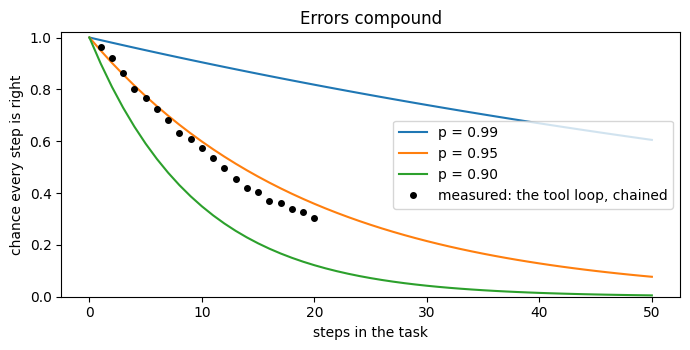


whole notebook: 254 s


In [19]:
print("chance that every step of a task is right:")
print("   steps      " + "".join(f"{n:>8d}" for n in [1, 5, 10, 20, 50]))
for p in [0.99, 0.95, 0.90]:
    print(f"   p = {p:.2f}   " + "".join(f"{p ** n:8.1%}" for n in [1, 5, 10, 20, 50]))
print(f"   0.95 ** 20 = {0.95 ** 20:.4f}    steps until a 95% step is a coin flip: {np.log(0.5) / np.log(0.95):.1f}")


def wrong_one_in(n, rng):
    def tool(a, op, b):
        return calculator(a, op, b) + (10 if rng.random() < 1 / n else 0)
    return tool


N_CHAINS, N_STEPS = 300, 20
chain_rng = np.random.default_rng(19)
noisy = {"CALC": wrong_one_in(20, chain_rng)}
totals = chain_rng.integers(10, 100, size=N_CHAINS)               # the true running totals
believed = totals.copy()                                          # what the agent thinks they are
step_right, chain_right = [], []
for n in range(1, N_STEPS + 1):
    add = chain_rng.integers(1, 10, size=N_CHAINS)
    runs = run_agent(tool_model, [(int(x), "+", int(a)) for x, a in zip(believed, add)], noisy)
    said = np.array([int(r["answer"]) if r["answer"] and r["answer"].isdigit() else -1 for r in runs])
    step_right.append(float(np.mean(said == believed + add)))     # was this one step right, given its input?
    totals = totals + add
    believed = np.where(said >= 0, said, believed + add)
    chain_right.append(float(np.mean(believed == totals)))
p_step = float(np.mean(step_right))
clean = np.mean([r["status"] == "answered" for r in runs])
print(f"\n{N_CHAINS} chains of {N_STEPS} steps: one step is right {p_step:.1%} of the time")
print("   steps            " + "".join(f"{n:>7d}" for n in [1, 2, 5, 10, 15, 20]))
print("   measured         " + "".join(f"{chain_right[n - 1]:7.1%}" for n in [1, 2, 5, 10, 15, 20]))
print("   0.95 ** n        " + "".join(f"{0.95 ** n:7.1%}" for n in [1, 2, 5, 10, 15, 20]))
print(f"   {p_step:.3f} ** n       " + "".join(f"{p_step ** n:7.1%}" for n in [1, 2, 5, 10, 15, 20]))
print(f"   runs in the last step that ended 'answered' with a clean log: {clean:.1%}")
print(f"   chains whose final total is wrong: {1 - chain_right[-1]:.1%}, and not one of them raised an error")

plt.figure(figsize=(7, 3.6))
ns = np.arange(0, 51)
for p in [0.99, 0.95, 0.90]:
    plt.plot(ns, p ** ns, label=f"p = {p:.2f}")
plt.plot(range(1, N_STEPS + 1), chain_right, "ko", markersize=4, label="measured: the tool loop, chained")
plt.xlabel("steps in the task"); plt.ylabel("chance every step is right"); plt.ylim(0, 1.02)
plt.title("Errors compound"); plt.legend(); plt.tight_layout(); plt.show()
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

### Why we see this

95% sounds like a good step. Twenty of them in a row succeed about 36% of the time, and after 14 steps the
task is a coin flip. The measured chains follow the same law: the whole-task score falls at every step
although no single step got any worse. They fall a little faster than 0.95 to the power n, because the tool's
one-in-twenty is not the only thing that can go wrong: now and then the model slips too, and the measured
per-step rate is 94.3%. Small sources of error do not replace one another. They multiply.

Notice also *how* the chains went wrong. Every run of every step ended `answered` with a clean log. A wrong
number entered at one step, was copied faithfully, became the question of the next step, and was carried to
the end. Nothing downstream could tell.

This is why single-step accuracy is the wrong number for a multi-step system, and why the engineering effort
in agents goes into three things: making each step more reliable (narrow tools, validation), making tasks
**shorter**, and adding checkpoints where an error is caught before the next step builds on it.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 8: `DIRECT_STEPS = 4000` | `seen kind` rises. Does `both large` rise with it? | |
| 2 | Step 3: remove the rule (delete the `continue` line) and retrain both | Which model's `both large` score changes most? | |
| 3 | Step 5: `retry = False` for every row (the model never sees `>E`), then rerun Step 15 | What does it write after its first error? | |
| 4 | Step 15: `max_steps=2` in the 200-question run | How many right answers are lost to an impatient limit? | |
| 5 | Step 17: make the tool return `0` for every call | Does the model still repeat it? Does any guard object? | |
| 6 | Step 16: `max_steps=3` | How many invented answers are stopped by the limit before they are written? | |
| 7 | Step 19: `wrong_one_in(100, chain_rng)` | Where is the curve after 20 steps? After how many steps is it a coin flip? | |
| 8 | Step 5: change `0.25` to `0.0` (the tool is never wrong in training) and retrain | Which column of the Step 12 table moves, and on which test set? | |

---
## Exercises

1. **A second tool.** Add the letter `R` to the alphabet and a tool `R(n)` that reverses the digits of n. Put it
   in `TOOLS`, extend `parse_call` to return the tool's name, and train on a mixture of both tasks. How often
   does the model call the wrong tool?
2. **Teach it to give up.** Add a line the model may write, `E` on its own, meaning "I cannot answer". Add
   training transcripts in which the tool fails twice and the right move is `E`. Rerun Step 16. How many
   made-up answers are left? Does the model now give up on questions it could have answered?
3. **A budget.** Give `run_agent` a character budget as well as a step limit, and stop when either runs out.
   Report both in the log. Which one would you rather be woken up for?
4. **Summarise the history.** When the context passes 48 characters, rebuild it as the question followed by
   only the latest call and result. Rerun the long log of Step 18. What changes, and what did the model lose
   that it might have needed?
5. **Two calls per question.** Write questions of the form `a*b+c?` whose transcript needs two calls, the
   second using the first result. Measure whole-task accuracy and compare it with the single-call accuracy
   squared.
6. **Informative errors.** Replace the single `>E` with two different marks, one for "malformed" and one for
   "tool failed", and train the model to respond differently to each (fix the call, or retry). Does a better
   error message improve recovery on `longer`?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| A tool call | text written by the model in an agreed format; nothing runs until a program reads it |
| The harness | parse → validate → execute → append the result → let the model continue |
| Who executes | your code, never the model; never `eval` model output |
| This lab's model | TinyGPT, V = 22, T = 64: 107,030 parameters, trained once per style |
| Graded positions | loss only on the model's own turns (`sample_weight`), not on questions or tool results |
| Direct model | must compute; breaks on pairings it has not seen |
| Tool-caller | must copy; survives new pairings, breaks on strings longer than it has copied |
| Three failures to count | malformed call (loud) · well-formed call, wrong arguments (quiet) · an answer from no tool result (quiet) |
| Parser | checks the shape of a call |
| Validator | checks that the call makes sense before it runs |
| Grounding rule | a final answer must equal a tool result; turns invented answers into visible stops |
| Step limit | lives in the harness; the model does not count its attempts |
| Tool results | enter the context and are treated as true, right or wrong |
| Out of its depth | a model does not stop; it writes the most plausible next line, which may be an invented answer |
| Compounding | n steps at p each: p to the power n. 0.95 to the 20th is 0.358 |
| The log | every model turn, every call, every result: without it a wrong answer cannot be traced |